# Homework 5 — Gravitational-Wave Course

## Exercise 1 — Numerical Computation of Derivatives

### Fourth-Order Finite Difference Method

In this exercise, we implement a numerical approximation of the first spatial derivative using a **fourth-order finite difference method**.

The derivative is approximated on a uniform grid with spacing $\Delta x$. For interior points, we use the centered fourth-order finite difference stencil:


$\left.\frac{df}{dx}\right|_{x_i}
\approx
\frac{
f_{i-2}-8f_{i-1}+8f_{i+1}-f_{i+2}
}{12\Delta x}$.


This approximation has a truncation error of order $(O(\Delta x^4))$.

To evaluate the derivative near the boundaries, we introduce **ghost points** outside the computational domain. These additional points allow us to apply the same centered stencil at every physical grid point.

We will test the numerical operator using functions with known analytical derivatives and investigate its convergence as the grid spacing is refined.

In [1]:
# Import libraries
import numpy as np
import matplotlib.pyplot as plt

print("NumPy version:", np.__version__)
print("Environment ready!")

NumPy version: 2.4.6
Environment ready!


# Finite Difference Operator

In [2]:
# The function will have 4 inputs:

def finite_difference_4th(f, dx, ghost_left, ghost_right):
    """
    Compute the first spatial derivative using a centered
    fourth-order finite difference stencil.

    Parameters
    ----------
    f : array
        Function values on the computational domain ("physical grid").

    dx : float
        Uniform spatial grid spacing.

    ghost_left : array
        Two ghost point values [f(-2), f(-1)].

    ghost_right : array
        Two ghost point values [f(N), f(N+1)].

    Returns
    -------
    df_dx : array
        Numerical derivative at every physical grid point.
    """


    f = np.asarray(f, dtype=float)
    ghost_left = np.asarray(ghost_left, dtype=float)
    ghost_right = np.asarray(ghost_right, dtype=float)

    # Check input dimensions
    if f.ndim != 1:
        raise ValueError("f must be a one-dimensional array.")

    if ghost_left.shape != (2,):
        raise ValueError("ghost_left must contain exactly 2 values.")

    if ghost_right.shape != (2,):
        raise ValueError("ghost_right must contain exactly 2 values.")

    # Verify that each array of ghost points has exactly two elements
    if dx <= 0:
        raise ValueError("dx must be positive.")

    # Extend the computational domain with ghost points - Building the grid:
    # Concatenating the ghost points with the physical values ​​to construct a single extended array.

    f_extended = np.concatenate([
        ghost_left,
        f,
        ghost_right
    ])

    # Allocate derivative array
    df_dx = np.zeros_like(f)

    # Applying the stencil: Fourth-order centered finite difference

    for i in range(len(f)):

        j = i + 2 # We compensate for the 2 fictitious points on the left.

        df_dx[i] = (
            f_extended[j-2]
            - 8*f_extended[j-1]
            + 8*f_extended[j+1]
            - f_extended[j+2]
        ) / (12*dx)

    return df_dx

# Test Function:
# $f(x)=\sin(x)$

Computational domain: $x\in[0,2\pi]$.


The domain is discretized using $N=101$ uniformly spaced grid points. The grid spacing is calculated as $\Delta x=x_{i+1}-x_i$.


Analytical derivative; $f'(x)=\cos(x)$.


In [3]:
# Define computational domain

x_min = 0.0
x_max = 2*np.pi

N = 101

x = np.linspace(x_min, x_max, N)

dx = x[1] - x[0]

# Define function - TEST FUNCTION

f = np.sin(x)

# Exact derivative

df_exact = np.cos(x)

print("Number of grid points:", N)
print("Grid spacing:", dx)


# Building the ghost points

x_left = np.array([
    x[0] - 2*dx,
    x[0] - dx
])

x_right = np.array([
    x[-1] + dx,
    x[-1] + 2*dx
])

# Ghost point values

ghost_left = np.sin(x_left)
ghost_right = np.sin(x_right)

print("Left ghost points:", ghost_left)
print("Right ghost points:", ghost_right)


Number of grid points: 101
Grid spacing: 0.06283185307179587
Left ghost points: [-0.12533323 -0.06279052]
Right ghost points: [0.06279052 0.12533323]


### Computing the numerical derivative

In [4]:
# Numerical derivative

df_numerical = finite_difference_4th(
    f,
    dx,
    ghost_left,
    ghost_right
)

# Calculate numerical error

error = np.abs(df_exact - df_numerical)

print("Maximum absolute error:", np.max(error))

Maximum absolute error: 5.19271052934478e-07


### Regarding the absolute error
The pointwise absolute error is:

$$
e_i=\left|f'_{\mathrm{exact}}(x_i)-f'_{\mathrm{numerical}}(x_i)\right|.
$$

For the chosen grid with $N=101$ points, the maximum absolute error is

$$
e_{\max}=5.19\times10^{-7}.
$$

The small error indicates that the numerical implementation accurately reproduces the analytical derivative for this test function.

## Plotting the derivative

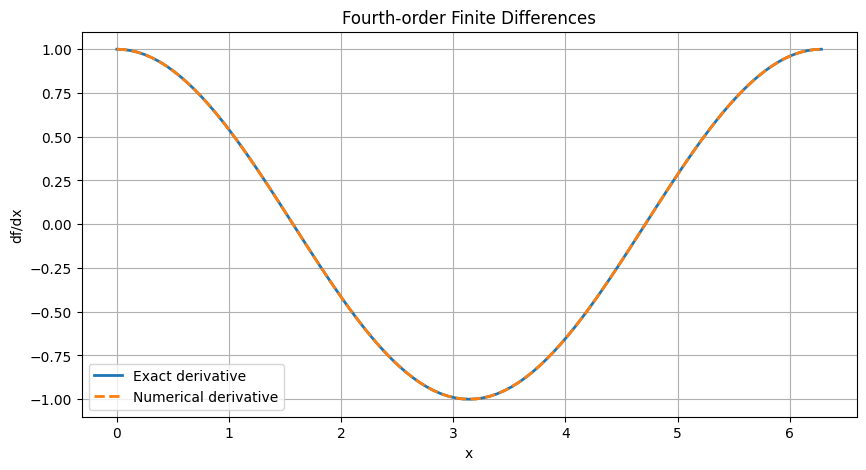

In [5]:
plt.figure(figsize=(10, 5))

plt.plot(
    x,
    df_exact,
    label="Exact derivative",
    linewidth=2
)

plt.plot(
    x,
    df_numerical,
    "--",
    label="Numerical derivative",
    linewidth=2
)

plt.xlabel("x")
plt.ylabel("df/dx")

plt.title("Fourth-order Finite Differences")

plt.legend()
plt.grid()

plt.show()

### Comparison Between Exact and Numerical Derivatives

The numerical and analytical derivatives overlap almost perfectly throughout the computational domain. This agreement is also observed near the boundaries, indicating that the ghost point treatment works correctly.

The plot provides a visual validation of the finite difference implementation.

# Convergence test

In [6]:
N_values = [26, 51, 101, 201, 401]

errors = []
dx_values = []

for N in N_values:

    # Computational domain
    x = np.linspace(0, 2*np.pi, N)

    dx = x[1] - x[0]

    # Function
    f = np.sin(x)

    # Exact derivative
    df_exact = np.cos(x)

    # Ghost points
    x_left = np.array([x[0]-2*dx, x[0]-dx])
    x_right = np.array([x[-1]+dx, x[-1]+2*dx])

    ghost_left = np.sin(x_left)
    ghost_right = np.sin(x_right)

    # Numerical derivative
    df_numerical = finite_difference_4th(
        f, dx, ghost_left, ghost_right
    )

    # Maximum error
    error = np.max(np.abs(df_exact - df_numerical))

    errors.append(error)
    dx_values.append(dx)

    print(f"N = {N:4d} | dx = {dx:.6e} | Error = {error:.6e}")

N =   26 | dx = 2.513274e-01 | Error = 1.319995e-04
N =   51 | dx = 1.256637e-01 | Error = 8.296630e-06
N =  101 | dx = 6.283185e-02 | Error = 5.192711e-07
N =  201 | dx = 3.141593e-02 | Error = 3.246589e-08
N =  401 | dx = 1.570796e-02 | Error = 2.029340e-09


# Calculate convergence order

In [7]:
for i in range(len(errors)-1):

    p = np.log(errors[i]/errors[i+1]) / np.log(dx_values[i]/dx_values[i+1])

    print(f"Convergence order: {p:.4f}")

Convergence order: 3.9919
Convergence order: 3.9980
Convergence order: 3.9995
Convergence order: 3.9998


### Numerical Convergence Order

We estimate the convergence order by comparing the maximum errors obtained at consecutive spatial resolutions.

Assuming that the numerical error scales as

$$
E(\Delta x)\approx C(\Delta x)^p,
$$

the convergence order is:

$$
p=
\frac{\log(E_i/E_{i+1})}
{\log(\Delta x_i/\Delta x_{i+1})}.
$$

The calculated convergence orders are approximately 3.99, 4.00, 4.00, and 4.00.

These results demonstrate that the numerical error decreases proportionally to the fourth power of the grid spacing, confirming the expected fourth-order convergence of the method.

### Log-log convergence plot

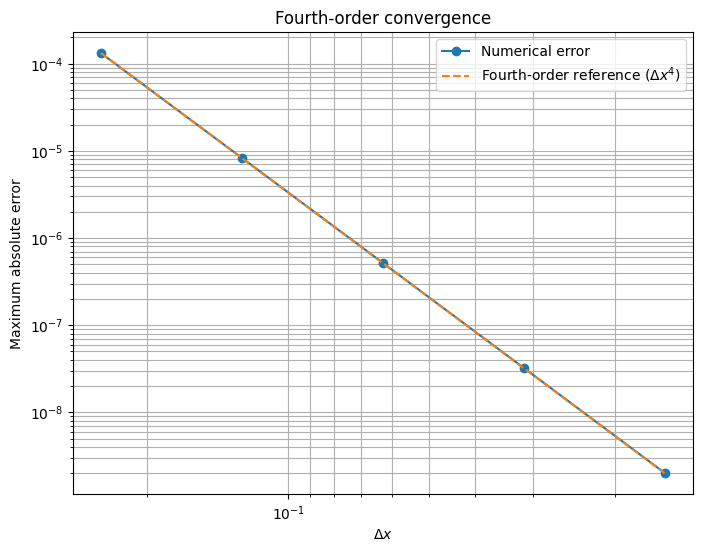

In [8]:
#Plots

plt.figure(figsize=(8,6))

plt.loglog(
    dx_values,
    errors,
    'o-',
    label="Numerical error"
)

# Reference fourth-order slope
reference = errors[0] * (np.array(dx_values)/dx_values[0])**4

plt.loglog(
    dx_values,
    reference,
    '--',
    label=r"Fourth-order reference ($\Delta x^4$)"
)

plt.xlabel(r"$\Delta x$")
plt.ylabel("Maximum absolute error")

plt.title("Fourth-order convergence")

plt.legend()
plt.grid(True, which="both")

plt.gca().invert_xaxis()

plt.show()

The numerical error follows the $\Delta x^4$ reference curve closely, providing a visual confirmation of the fourth-order convergence obtained from the numerical estimates.

# Interior and boundary errors (separately)

In [9]:
# Separate interior and boundary errors

# Recompute the pointwise numerical error
error_array = np.abs(df_exact - df_numerical)

# Interior points: stencil does not use ghost points
error_interior = error_array[2:-2]

# Boundary points: stencil uses ghost points
error_boundary = np.concatenate([
    error_array[:2],
    error_array[-2:]
])

# Maximum absolute errors
max_error_interior = np.max(error_interior)
max_error_boundary = np.max(error_boundary)

print("Maximum error in the interior:", max_error_interior)
print("Maximum error near the boundaries:", max_error_boundary)

Maximum error in the interior: 2.0292856284243044e-09
Maximum error near the boundaries: 2.0293399183302085e-09


### Interior and Boundary Error Analysis

To verify that the finite difference operator works correctly throughout the computational domain, we evaluate the numerical error separately at interior points and near the boundaries.

The maximum absolute errors are

- Interior: $2.0293\times10^{-9}$.
- Boundary: $2.0293\times10^{-9}$.

The two errors are practically identical, showing that the use of ghost points allows the centered fourth-order stencil to maintain its accuracy near the boundaries.

Therefore, the implementation correctly evaluates the numerical derivative both at interior points and near the boundaries, as required.

# Test Function: Exponential function

In [10]:
# Define test function

f_exp = np.exp(x)

# Exact derivative

df_exp_exact = np.exp(x)

# Ghost points

ghost_left_exp = np.exp(x_left)
ghost_right_exp = np.exp(x_right)

# Numerical derivative

df_exp_numerical = finite_difference_4th(
    f_exp,
    dx,
    ghost_left_exp,
    ghost_right_exp
)

# Calculate absolute error

error_exp = np.abs(df_exp_exact - df_exp_numerical)

# Separate interior and boundary errors

error_exp_interior = error_exp[2:-2]

error_exp_boundary = np.concatenate([
    error_exp[:2],
    error_exp[-2:]
])

print("Maximum absolute error:", np.max(error_exp))

print("Maximum error in the interior:",
      np.max(error_exp_interior))

print("Maximum error near the boundaries:",
      np.max(error_exp_boundary))

Maximum absolute error: 1.0867603350561694e-06
Maximum error in the interior: 1.0531081215958693e-06
Maximum error near the boundaries: 1.0867603350561694e-06


### Results for the Exponential Test Function

For the second test:
$f(x)=e^x$

whose analytical derivative is $
f'(x)=e^x.
$

The maximum absolute errors obtained are:

- Entire domain: $1.0868\times10^{-6}$.
- Interior points: $1.0531\times10^{-6}$.
- Boundary points: $1.0868\times10^{-6}$.

The numerical derivative agrees well with the analytical result. The errors in the interior and near the boundaries are of comparable magnitude, providing further evidence that the ghost point treatment works correctly.

